In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import joblib
from pathlib import Path



In [32]:
df = pd.read_csv("data/Dataset.csv")

In [33]:
df.head(                                                    )

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [34]:
df.tail(                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    )

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV
8789,s8786,TV Show,YOM,Not Given,Pakistan,6/7/2018,2016,TV-Y7,1 Season,Kids' TV


In [35]:
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [36]:
print(df.shape)


(8790, 10)


In [37]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB
None


In [38]:
print(df.isnull().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [39]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nAudience Rating Distribution:")
print(df["rating"].value_counts(dropna=False))

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (8790, 10)

Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Audience Rating Distribution:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [40]:
rating_counts = df["rating"].value_counts()

df["rating_group"] = df["rating"].where(
    df["rating"].map(rating_counts) >= 50,
    "Other"
)

print("Rating Classes:")
print(df["rating_group"].value_counts())

Rating Classes:
rating_group
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Other      53
Name: count, dtype: int64


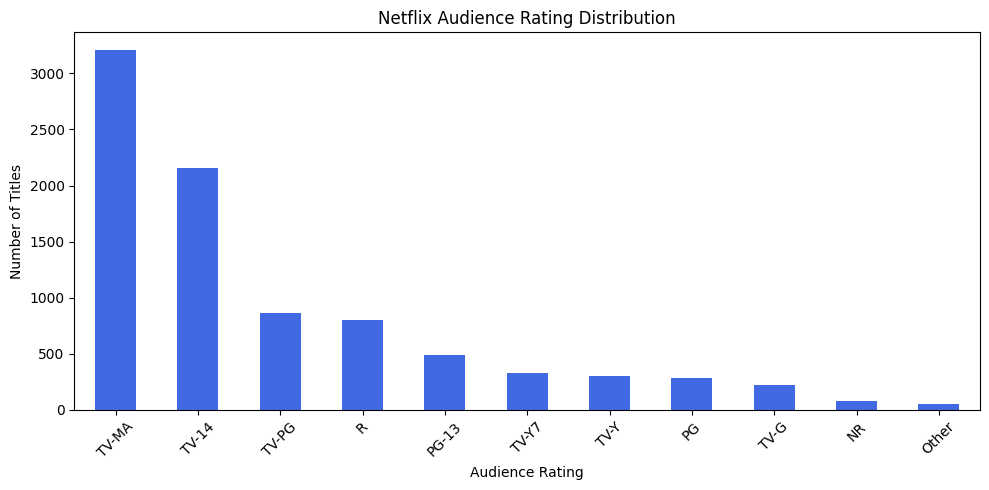

In [41]:
plt.figure(figsize=(10, 5))

df["rating_group"].value_counts().plot(
    kind="bar",
    color="royalblue"
)

plt.title("Netflix Audience Rating Distribution")
plt.xlabel("Audience Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
features = [
    "type",
    "release_year",
    "country",
    "listed_in",
    "duration",
    "director"
]

X = df[features].copy()

y = df["rating_group"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X.head()

X Shape: (8790, 6)
y Shape: (8790,)


,type,release_year,country,listed_in,duration,director
0,Movie,2020,United States,Documentaries,90 min,Kirsten Johnson
1,TV Show,2021,France,"Crime TV Shows, International TV Shows, TV Act...",1 Season,Julien Leclercq
2,TV Show,2021,United States,"TV Dramas, TV Horror, TV Mysteries",1 Season,Mike Flanagan
3,Movie,2021,Brazil,"Children & Family Movies, Comedies",91 min,Bruno Garotti
4,Movie,1993,United States,"Dramas, Independent Movies, International Movies",125 min,Haile Gerima


In [43]:
categorical_features = [
    "type",
    "country"
]

numeric_features = [
    "release_year"
]

text_features = [
    "listed_in",
    "duration",
    "director"
]

print("Categorical:", categorical_features)
print("Numerical:", numeric_features)
print("Text:", text_features)

Categorical: ['type', 'country']
Numerical: ['release_year']
Text: ['listed_in', 'duration', 'director']


In [44]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "genres",
            TfidfVectorizer(max_features=300),
            "listed_in"
        ),
        (
            "duration_text",
            TfidfVectorizer(max_features=100),
            "duration"
        ),
        (
            "director_text",
            TfidfVectorizer(max_features=200),
            "director"
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (7032, 6)
Testing Data: (1758, 6)


In [46]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

print("Models created successfully!")

Models created successfully!


In [47]:
from sklearn.base import clone

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    trained_models[name] = pipeline

    print(f"{name}: {accuracy:.4f}")

Logistic Regression: 0.5358
Decision Tree: 0.5000
Random Forest: 0.5228


In [48]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print("MODEL COMPARISON")
print(results_df.to_string(index=False))

MODEL COMPARISON
              Model  Accuracy
Logistic Regression  0.535836
      Random Forest  0.522753
      Decision Tree  0.500000


In [49]:
best_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_name]

best_pred = best_model.predict(X_test)

print("BEST MODEL:", best_name)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        best_pred,
        zero_division=0
    )
)

BEST MODEL: Logistic Regression

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          NR       0.00      0.00      0.00        16
       Other       0.75      0.27      0.40        11
          PG       0.46      0.53      0.49        57
       PG-13       0.43      0.36      0.39        98
           R       0.54      0.58      0.56       160
       TV-14       0.50      0.50      0.50       431
        TV-G       0.00      0.00      0.00        44
       TV-MA       0.59      0.74      0.66       641
       TV-PG       0.37      0.14      0.20       172
        TV-Y       0.53      0.61      0.56        61
       TV-Y7       0.52      0.51      0.51        67

    accuracy                           0.54      1758
   macro avg       0.43      0.38      0.39      1758
weighted avg       0.50      0.54      0.51      1758



In [50]:
Path("../models").mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    best_model,
    "../models/netflix_rating_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


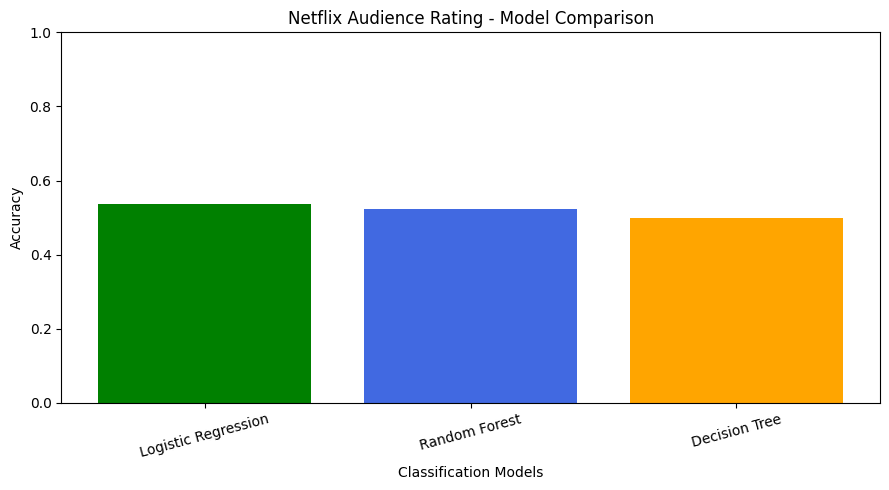

In [51]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"],
    color=["green", "royalblue", "orange"]
)

plt.title("Netflix Audience Rating - Model Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

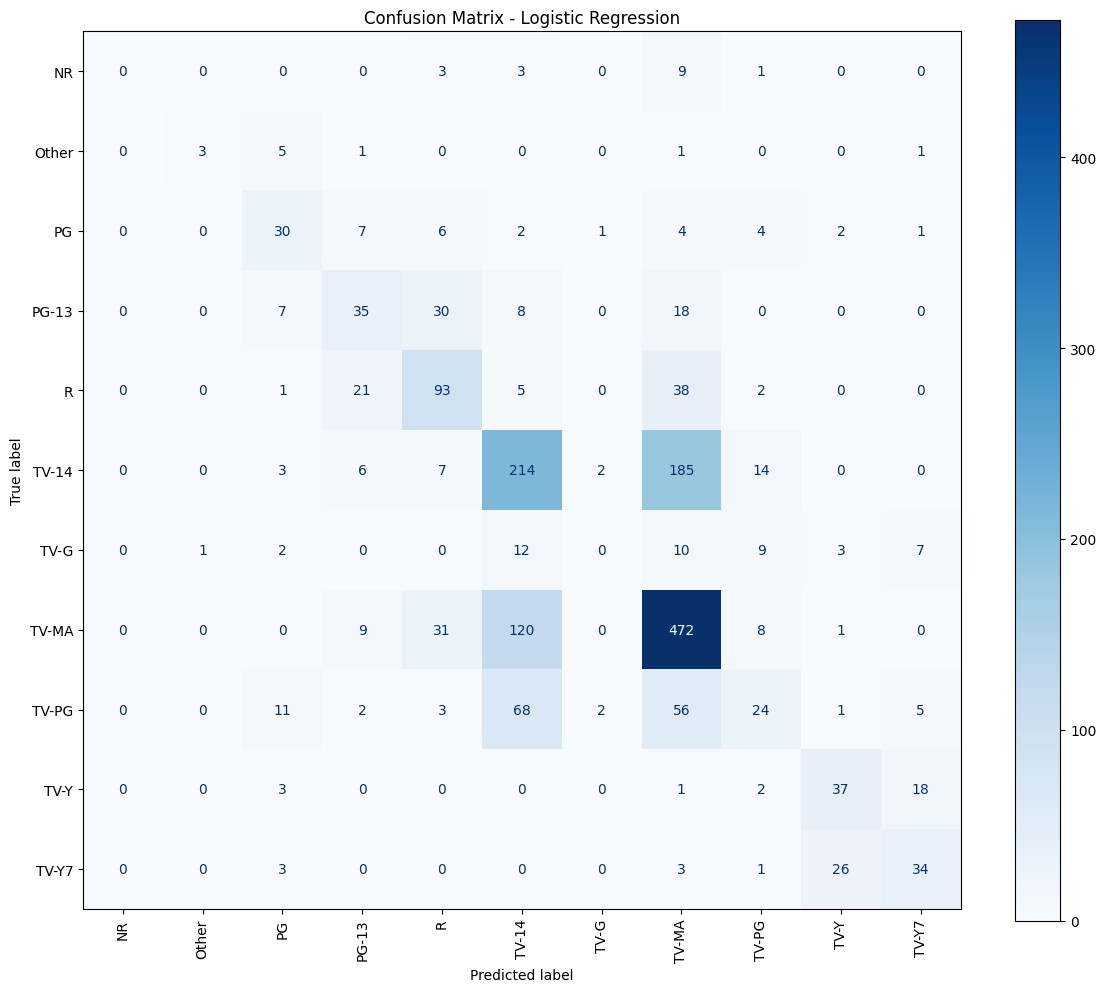

In [52]:
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    ax=ax,
    xticks_rotation=90,
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_name}")

plt.tight_layout()
plt.show()

In [53]:
balanced_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

print("Balanced Model Accuracy:",
      accuracy_score(y_test, balanced_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    balanced_pred,
    zero_division=0
))

Balanced Model Accuracy: 0.45164960182025027

Classification Report:
              precision    recall  f1-score   support

          NR       0.04      0.25      0.07        16
       Other       0.14      0.36      0.20        11
          PG       0.39      0.54      0.46        57
       PG-13       0.33      0.54      0.41        98
           R       0.45      0.54      0.49       160
       TV-14       0.52      0.47      0.49       431
        TV-G       0.11      0.27      0.16        44
       TV-MA       0.70      0.46      0.55       641
       TV-PG       0.26      0.22      0.24       172
        TV-Y       0.49      0.59      0.54        61
       TV-Y7       0.47      0.52      0.50        67

    accuracy                           0.45      1758
   macro avg       0.36      0.43      0.37      1758
weighted avg       0.52      0.45      0.47      1758



In [54]:
from sklearn.base import clone

In [55]:
from sklearn.metrics import f1_score

comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, best_pred),
        accuracy_score(y_test, balanced_pred)
    ],
    "Macro F1": [
        f1_score(y_test, best_pred, average="macro"),
        f1_score(y_test, balanced_pred, average="macro")
    ]
})

comparison

,Model,Accuracy,Macro F1
0,Original Logistic Regression,0.535836,0.388412
1,Balanced Logistic Regression,0.451650,0.373141


In [56]:


final_model = trained_models["Logistic Regression"]

Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_model,
    "../models/netflix_rating_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [57]:
sample = pd.DataFrame({
    "type": ["Movie"],
    "release_year": [2022],
    "country": ["United States"],
    "listed_in": ["Action & Adventure, Dramas"],
    "duration": ["120 min"],
    "director": ["Unknown"]
})

prediction = final_model.predict(sample)

print("Predicted Audience Rating:", prediction[0])

Predicted Audience Rating: R


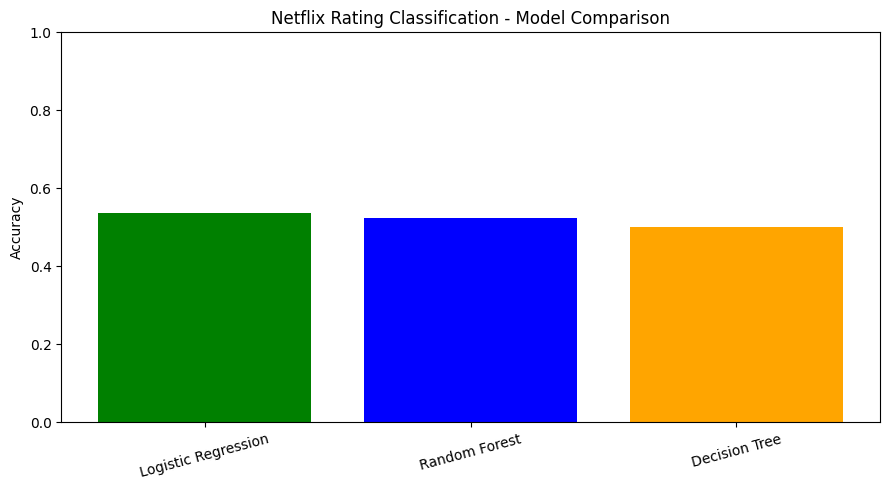

In [58]:
Path("../screenshots").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"],
    color=["green", "blue", "orange"]
)

plt.title("Netflix Rating Classification - Model Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "../screenshots/model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

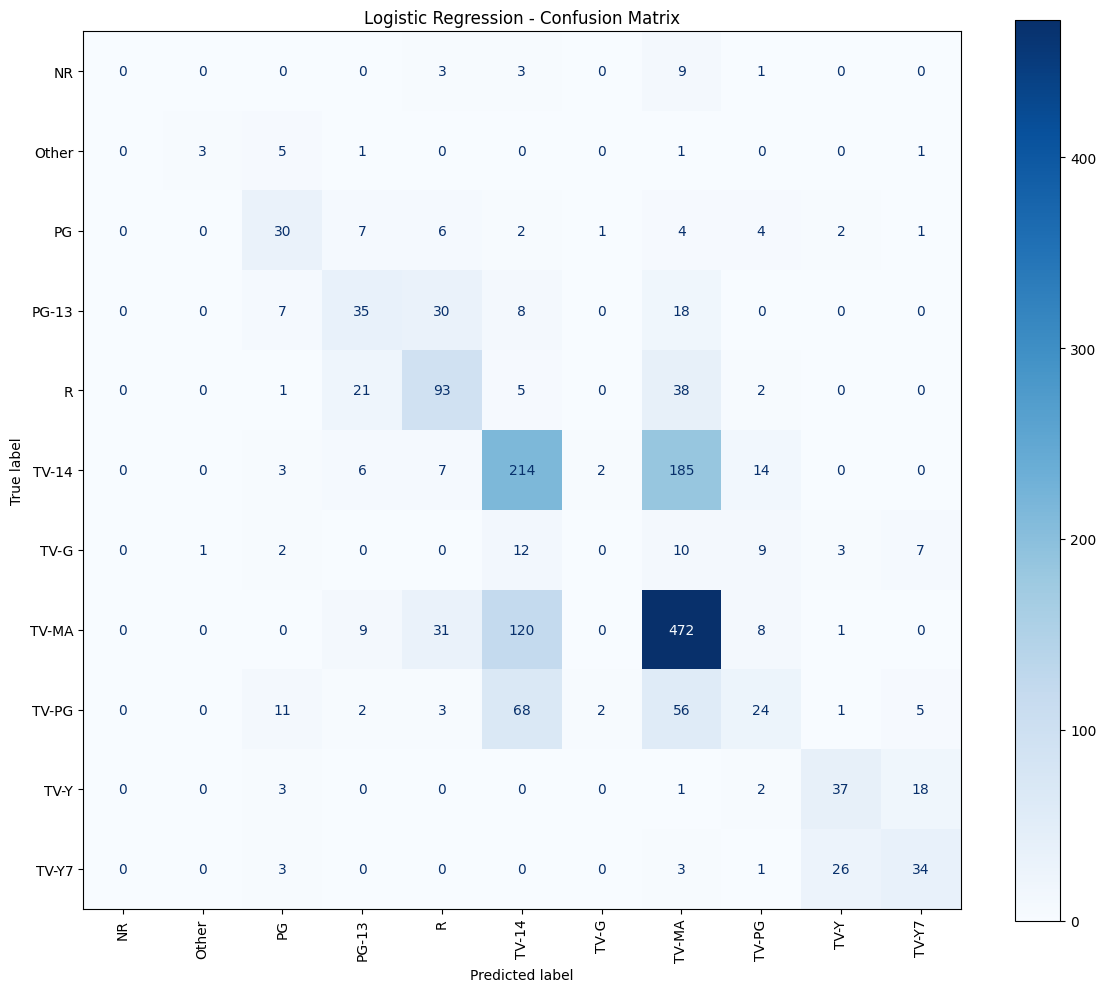

In [59]:
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    ax=ax,
    xticks_rotation=90,
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../screenshots/confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [61]:
                                
final_model = trained_models["Logistic Regression"]
model_path = Path("../models/netflix_rating_model.pkl")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Model location:", model_path.resolve())

Model saved successfully!
Model location: /home/sourabh/models/netflix_rating_model.pkl
